In [1]:

import pandas as pd

df = pd.read_csv('/content/train.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
C

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [3]:

# Create a copy so the original data remains unchanged
clean_df = df.copy()

# Fill missing Age values with the median
clean_df['Age'] = clean_df['Age'].fillna(
    clean_df['Age'].median()
)

# Fill missing Embarked values with the mode
clean_df['Embarked'] = clean_df['Embarked'].fillna(
    clean_df['Embarked'].mode()[0]
)

# Drop Cabin because most values are missing
clean_df = clean_df.drop(columns=['Cabin'])

print("Missing values handled!")
print("\nRemaining missing values:")
print(clean_df.isnull().sum())

print("\nCleaned dataset shape:", clean_df.shape)


Missing values handled!

Remaining missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Cleaned dataset shape: (891, 11)


In [4]:

print("Duplicate rows:", clean_df.duplicated().sum())

print("\nSurvival counts:")
print(clean_df['Survived'].value_counts())

print("\nSurvival percentages:")
print(
    (clean_df['Survived'].value_counts(normalize=True) * 100)
    .round(2)
)


Duplicate rows: 0

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


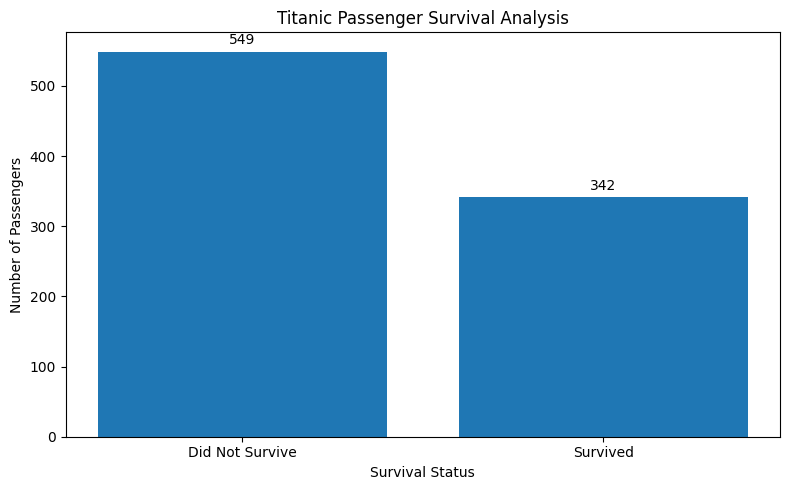

In [5]:

import matplotlib.pyplot as plt

survival_counts = clean_df['Survived'].value_counts().sort_index()

labels = ['Did Not Survive', 'Survived']
values = [survival_counts[0], survival_counts[1]]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.title('Titanic Passenger Survival Analysis')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')

plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.savefig('titanic_survival_analysis.png', dpi=300, bbox_inches='tight')
plt.show()


Survival percentage by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


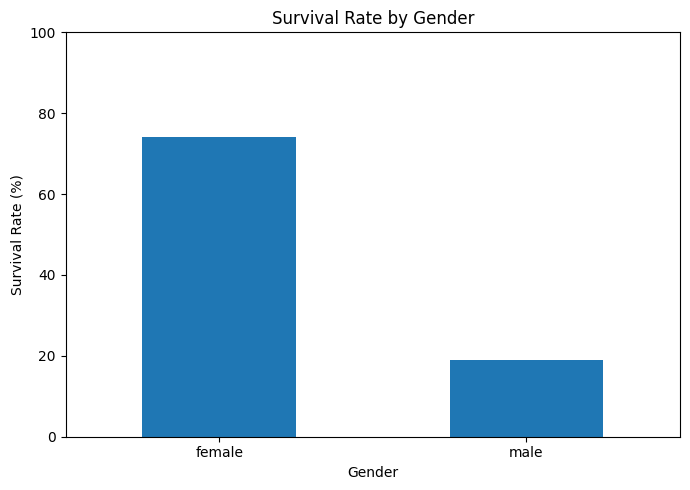

In [6]:

import matplotlib.pyplot as plt

gender_survival = clean_df.groupby('Sex')['Survived'].mean() * 100

print("Survival percentage by gender:")
print(gender_survival.round(2))

gender_survival.plot(kind='bar', figsize=(7, 5))

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig('titanic_gender_survival.png', dpi=300, bbox_inches='tight')
plt.show()


Survival percentage by passenger class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


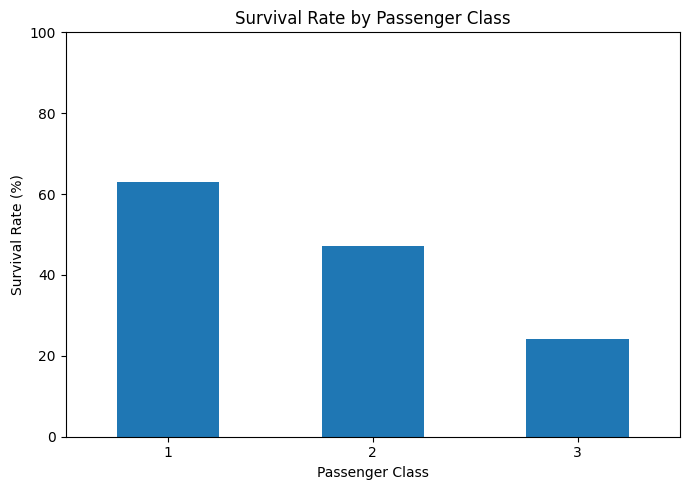

In [7]:

import matplotlib.pyplot as plt

class_survival = clean_df.groupby('Pclass')['Survived'].mean() * 100

print("Survival percentage by passenger class:")
print(class_survival.round(2))

class_survival.plot(kind='bar', figsize=(7, 5))

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig(
    'titanic_class_survival.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


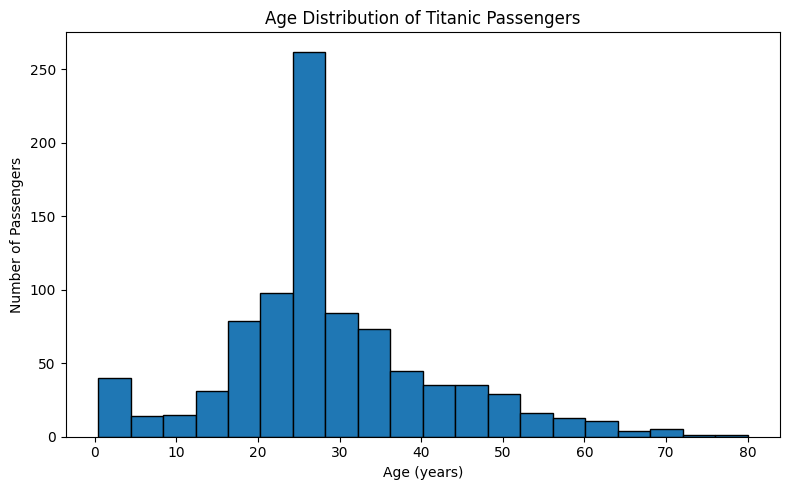

In [8]:

plt.figure(figsize=(8, 5))

plt.hist(clean_df['Age'], bins=20, edgecolor='black')

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age (years)')
plt.ylabel('Number of Passengers')

plt.tight_layout()
plt.savefig('titanic_age_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


# Task 2: Data Cleaning and Exploratory Data Analysis (EDA) — Titanic Dataset

## Objective
To clean and analyze the Titanic passenger dataset and identify patterns related to passenger survival using Python.

## Dataset
The dataset was obtained from the Titanic competition files provided in the Prodigy InfoTech data-science-datasets repository. The training dataset contains 891 rows and 12 columns.

## Tools and Libraries
- Python
- Pandas
- Matplotlib
- Google Colab

## Data Cleaning
1. Inspected the dataset structure, data types, and missing values.
2. Found 177 missing values in Age, 687 in Cabin, and 2 in Embarked.
3. Filled missing Age values using the median.
4. Filled missing Embarked values using the mode.
5. Dropped Cabin because most of its values were missing.
6. Checked for duplicate rows; none were found.
7. Verified that the cleaned dataset had no remaining missing values.

The cleaned dataset contains 891 rows and 11 columns.

## Exploratory Data Analysis and Key Findings
- Out of 891 passengers, 342 survived (38.38%) and 549 did not survive (61.62%).
- The survival rate for female passengers was 74.20%, compared with 18.89% for male passengers.
- The survival rate was 62.96% for First Class, 47.28% for Second Class, and 24.24% for Third Class.
- The age histogram shows that many passengers were in the approximate 20–35 age range.

## Conclusion
This analysis demonstrates the importance of data cleaning and exploratory data analysis. Missing values were handled, duplicate rows were checked, and visualizations were created to explore survival patterns. In this dataset, survival rates differed substantially by gender and passenger class. These findings describe patterns in the training data and do not, by themselves, establish causation.